<a href="https://colab.research.google.com/github/InowaR/colab/blob/main/estimate_drift_correction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Истина   (base -> rotated): angle=+20.0000°, tx=+10.0000, ty=+5.0000
Ожидаемо (rotated -> base): angle=-20.0000°, tx=-11.1070, ty=-1.2783
Найдено:                    angle=-20.0000°, tx=-11.1070, ty=-1.2783
Ошибка восстановления (mean NN): 2.259724e-15


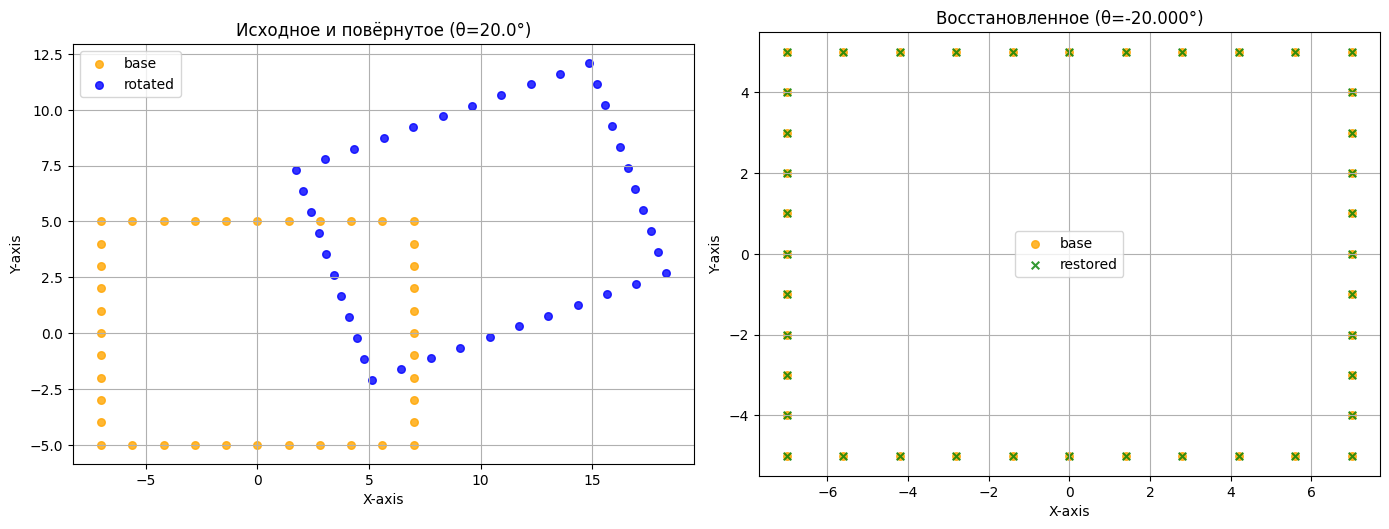

In [48]:
import numpy as np
import matplotlib.pyplot as plt


def rotation_matrix(angle_degrees):
    """Матрица поворота на заданный угол (в градусах)."""
    angle_radians = np.radians(angle_degrees)
    cos_a, sin_a = np.cos(angle_radians), np.sin(angle_radians)
    return np.array([[cos_a, -sin_a],
                     [sin_a,  cos_a]])


def transform_points(points, angle_degrees, shift_x, shift_y):
    """Поворот точек на angle_degrees вокруг начала координат и сдвиг на (shift_x, shift_y)."""
    return points @ rotation_matrix(angle_degrees).T + [shift_x, shift_y]


def estimate_rigid_transform(source_points, target_points):
    """
    Оценка параметров жёсткого преобразования (поворот + сдвиг),
    при котором R(angle)·source + shift ≈ target.

    Сдвиг исключается центрированием облака точек.
    Угол находится аналитически (2D Procrustes).
    Возвращает (angle_degrees, shift_x, shift_y).
    """
    source_center = source_points.mean(axis=0)
    target_center = target_points.mean(axis=0)
    source_centered = source_points - source_center
    target_centered = target_points - target_center

    # Скалярное и векторное произведения соответствующих пар точек
    cross_sum = np.sum(source_centered[:, 0] * target_centered[:, 1]
                       - source_centered[:, 1] * target_centered[:, 0])
    dot_sum = np.sum(source_centered[:, 0] * target_centered[:, 0]
                     + source_centered[:, 1] * target_centered[:, 1])

    angle_degrees = np.degrees(np.arctan2(cross_sum, dot_sum))

    shift = target_center - rotation_matrix(angle_degrees) @ source_center
    return angle_degrees, shift[0], shift[1]


def create_rectangle_perimeter(x_min, y_min, x_max, y_max,
                                points_per_horizontal=10,
                                points_per_vertical=10):
    """Возвращает точки, равномерно распределённые по периметру прямоугольника."""
    corners = [(x_min, y_min), (x_max, y_min), (x_max, y_max), (x_min, y_max)]
    perimeter_points = []

    for side_index in range(4):
        start = np.array(corners[side_index])
        end = np.array(corners[(side_index + 1) % 4])

        points_on_side = (points_per_horizontal if side_index % 2 == 0
                          else points_per_vertical)
        fractions = np.linspace(0, 1, points_on_side + 1)[:-1, None]
        perimeter_points.append(start + fractions * (end - start))

    return np.vstack(perimeter_points)


# ---------- Сценарий ----------
base_points = create_rectangle_perimeter(-7, -5, 7, 5)

TRUE_ANGLE, TRUE_SHIFT_X, TRUE_SHIFT_Y = 20.0, 10.0, 5.0
rotated_points = transform_points(base_points, TRUE_ANGLE, TRUE_SHIFT_X, TRUE_SHIFT_Y)

# Ищем обратное преобразование: rotated -> base
found_angle, found_shift_x, found_shift_y = estimate_rigid_transform(rotated_points, base_points)
restored_points = transform_points(rotated_points, found_angle, found_shift_x, found_shift_y)

# Ожидаемые параметры обратного преобразования (аналитически)
inverse_rotation = rotation_matrix(-TRUE_ANGLE)
expected_shift = -inverse_rotation @ np.array([TRUE_SHIFT_X, TRUE_SHIFT_Y])

print(f"Истина   (base -> rotated): angle={TRUE_ANGLE:+.4f}°, "
      f"tx={TRUE_SHIFT_X:+.4f}, ty={TRUE_SHIFT_Y:+.4f}")
print(f"Ожидаемо (rotated -> base): angle={-TRUE_ANGLE:+.4f}°, "
      f"tx={expected_shift[0]:+.4f}, ty={expected_shift[1]:+.4f}")
print(f"Найдено:                    angle={found_angle:+.4f}°, "
      f"tx={found_shift_x:+.4f}, ty={found_shift_y:+.4f}")
print(f"Ошибка восстановления (mean NN): "
      f"{np.mean(np.linalg.norm(restored_points - base_points, axis=1)):.6e}")

# ---------- Визуализация ----------
figure, axes = plt.subplots(1, 2, figsize=(14, 6))

plots = [
    (axes[0], rotated_points, 'blue', 'o', 'rotated',
     f'Исходное и повёрнутое (θ={TRUE_ANGLE}°)'),
    (axes[1], restored_points, 'green', 'x', 'restored',
     f'Восстановленное (θ={found_angle:.3f}°)'),
]

for axis, points, color, marker, label, title in plots:
    axis.scatter(*base_points.T, c='orange', marker='o', s=30, alpha=0.8, label='base')
    axis.scatter(*points.T, c=color, marker=marker, s=30, alpha=0.8, label=label)
    axis.set(xlabel='X-axis', ylabel='Y-axis', title=title)
    axis.grid(True)
    axis.legend()
    axis.set_aspect('equal')

plt.tight_layout()
plt.show()